# Module E — Crisis Event Analysis
**Project:** Is There Still a Diversification Benefit to Emerging Markets? (UCSD Quantitative Finance Capstone)

**Question.** How did MSCI Emerging Markets (EM) perform *relative to* MSCI World around 15 named crises, from 5 trading days before to 20 trading days after the event, and does the pattern differ between past and current crises, and between financial, geopolitical and trade shocks?

**Method (follows the team's existing definition, nothing new is invented):**
- Daily log returns (%) of MSCI EM (USD net total return) and MSCI World (net total return), joined on the dates where both are quoted.
- Relative return = EM − World, in log-return points.
- Day 0 = first trading day on or after the event date.
- Cumulative relative return `CAR[-5, k]` = sum of daily relative returns from Day −5 through Day k (the Day −5 return is included, as in the team's code).
- Events, dates and labels are read from `analysis/config.py` in the uploaded project, **not** typed in again.

**Revision (v2).** Changes to the first version, so the event study lines up with the team's crisis regression (equation 2):
1. **War and trade together.** In equation (2), `Geo` = GPR *or* TPU in its top decile, so current trade conflicts are part of Geo. The past-vs-current comparison for Geo now uses current war + trade (7 events) next to γ4. War-only (3 events) is still shown.
2. **Like-for-like comparison.** The pooled "all past vs all current" average mixes crisis types (no past trade events, 3 vs 2 financial events). Past and current are now compared within each type.
3. **Size against normal times.** Each CAR is compared with the normal variation of EM − World: a t-statistic using daily volatility in the 245 trading days before the window, and the CAR's percentile among all 26-day windows since 2001.
4. **Country breakdown (new data).** The top-8 EM country indices split each crisis's EM − World result into country contributions, to see whether a crisis window was driven by the crisis or by an unrelated country move.
5. Colours match the team report (past = blue, current = orange); the unused `first_ok` check is now an actual check.

**Notebook outline:** 1) Inspect data and events → 2) Compute CARs → 3) Per-crisis table → 4) Group averages and like-for-like comparison → 5) Size against normal times → 6) Country breakdown → 7) Charts → 8) Reconcile with the team's CSVs → 9) Findings and link to Module D.

*How to run:* put `Globeflex-b.zip` (or the unzipped folder) in Downloads, Desktop, Documents or next to this notebook, then use Kernel → Restart & Run All. The first cell finds the project, and unzips the zip automatically if needed; if it still cannot find it, set `PROJECT_ROOT` in that cell. Needs only `pandas`, `numpy`, `matplotlib`, `openpyxl`. Outputs go to `output/module_e/` and never overwrite the team's files.

In [1]:
%matplotlib inline
import importlib.util
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

PROJECT_ROOT = None   # leave None to auto-detect; if it fails, paste the full path of the unzipped project folder here


TARGET = Path("data") / "MSCI EM Returns daily.xlsx"
ZIP_NAME = "Globeflex-b.zip"


def search_folder(base, max_depth):
    # Look for <base>/[*/]*/data/MSCI EM Returns daily.xlsx down to max_depth levels
    if (base / TARGET).exists():
        return base
    for depth in range(1, max_depth + 1):
        for hit in base.glob("/".join(["*"] * depth) + "/" + TARGET.as_posix()):
            return hit.parents[1]
    return None


def find_root():
    cwd, home = Path.cwd().resolve(), Path.home()
    for base in [cwd, *cwd.parents]:                                   # 1) current folder and its parents
        if (base / TARGET).exists():
            return base
    places = [cwd, home / "Downloads", home / "Desktop", home / "Documents", home]
    for base in places:                                                # 2) an unzipped project in common places
        if base.exists():
            hit = search_folder(base, 3 if base == home else 4)
            if hit:
                return hit
    for base in places:                                                # 3) only the zip exists: unzip it next to the notebook
        z = base / ZIP_NAME
        if z.exists():
            dest = cwd / "Globeflex-b_unzipped"
            if not dest.exists():
                zipfile.ZipFile(z).extractall(dest)
            hit = search_folder(dest, 4)
            if hit:
                return hit
    raise FileNotFoundError(
        "Could not find the project data. Either unzip Globeflex-b.zip, or set PROJECT_ROOT in this cell, e.g.\n"
        '  PROJECT_ROOT = "/Users/yourname/Downloads/Globeflex-b/Globeflex-b"   (Mac)\n'
        '  PROJECT_ROOT = r"C:\\Users\\yourname\\Downloads\\Globeflex-b\\Globeflex-b"   (Windows)\n'
        "The folder you point to must contain data/ and analysis/."
    )


ROOT = Path(PROJECT_ROOT) if PROJECT_ROOT else find_root()
DATA_DIR = ROOT / "data"
TEAM_TABLES = ROOT / "output" / "tables"          # teammates' results (read only)
OUT_DIR = ROOT / "output" / "module_e"            # this notebook's outputs
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /home/user/Globeflex-b


## 1. Inspect the uploaded files
### 1.1 Raw data and the team's existing results

In [2]:
print("data/ folder:")
for p in sorted(DATA_DIR.iterdir()):
    print(f"  {p.name:60s} {p.stat().st_size/1024:8.0f} KB")

print("\nTeam result tables relevant to Module E / Module D:")
for name in ["step3_event_study.csv", "step3_event_study_by_group.csv", "step3_event_paths_daily.csv",
             "q2_table2_event_study.csv", "q2_table2_event_study_by_group.csv",
             "step3_crisis_regressions.csv", "step3_crisis_regressions_pvalues.csv"]:
    print(f"  {name:45s}", "found" if (TEAM_TABLES / name).exists() else "MISSING")

data/ folder:
  Country_mktcap_monthly.xlsx                                        66 KB
  Country_returns_daily.xlsx                                        739 KB
  DXY daily.xlsx                                                    169 KB
  EMSC.xlsx                                                         228 KB
  GPR monthly.xls                                                  2289 KB
  MSCI EM INDX MARKET_CAP_MONTHLY.xlsx                               61 KB
  MSCI EM IT market cap & returns.xlsx                              132 KB
  MSCI EM Returns daily.xlsx                                        145 KB
  MSCI EM price index.xlsx                                          173 KB
  MSCI Emerging Net Total Return Local Index.xlsx                   134 KB
  MSCI USA  net total return.xlsx                                   151 KB
  MSCI USA IT.xlsx                                                  141 KB
  MSCI WORLD net total return.xlsx                                  152 KB
  TPU month

In [3]:
def read_levels(fname):
    # Same reading rule as the team's data_prep.py: first two columns = date, index level.
    df = pd.read_excel(DATA_DIR / fname, header=None).iloc[:, :2]
    df.columns = ["date", "level"]
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["level"] = pd.to_numeric(df["level"], errors="coerce")
    return df.dropna().set_index("date")["level"].sort_index()


em_lv = read_levels("MSCI EM Returns daily.xlsx")             # MSCI EM, USD net total return
world_lv = read_levels("MSCI WORLD net total return.xlsx")    # MSCI World, net total return

qc = pd.DataFrame({
    name: {"first date": s.index.min().date(), "last date": s.index.max().date(), "observations": len(s),
           "duplicate dates": int(s.index.duplicated().sum()), "non-positive levels": int((s <= 0).sum()),
           "zero-return days since 2001": int((s.loc["2001":].pct_change() == 0).sum())}
    for name, s in {"MSCI EM (net, USD)": em_lv, "MSCI World (net)": world_lv}.items()
})
qc

,"MSCI EM (net, USD)",MSCI World (net)
first date,1998-12-31,1990-01-31
last date,2026-09-25,2026-09-25
observations,7237,7344
duplicate dates,0,0
non-positive levels,0,0
zero-return days since 2001,2,9


### 1.2 The 15 crises (read from the team's `config.py`)

In [4]:
spec = importlib.util.spec_from_file_location("team_config", ROOT / "analysis" / "config.py")
cfg = importlib.util.module_from_spec(spec)
spec.loader.exec_module(cfg)

PRE, POST = cfg.EVENT_PRE, cfg.EVENT_POST
events = pd.DataFrame(cfg.CRISES, columns=["crisis", "date", "type", "period"])
events["date"] = pd.to_datetime(events["date"])
events = events.set_index("crisis")
events["group"] = events["period"] + " " + events["type"]

print(f"Event window: Day -{PRE} to Day +{POST}   |   number of events: {len(events)}")
display(events[["date", "type", "period"]])
display(pd.crosstab(events["period"], events["type"], margins=True))

Event window: Day -5 to Day +20   |   number of events: 15


,date,type,period
crisis,,,
Lehman bankruptcy,2008-09-15,Fin,Past
US downgrade / euro crisis,2011-08-08,Fin,Past
China devaluation,2015-08-11,Fin,Past
9/11 attacks,2001-09-11,Geo,Past
Iraq invasion,2003-03-20,Geo,Past
Crimea annexation,2014-03-03,Geo,Past
COVID crash,2020-02-24,Fin,Current
SVB collapse,2023-03-10,Fin,Current
Russia invades Ukraine,2022-02-24,Geo,Current


type,Fin,Geo,Trade,All
period,,,,
Current,2,3,4,9
Past,3,3,0,6
All,5,6,4,15


*Legend:* `Fin` = financial crisis, `Geo` = war / geopolitical, `Trade` = trade conflict; `Past` = before 2018, `Current` = from 2018 (the team's definition — e.g. COVID is labelled *Current*).
Six past events (3 Fin, 3 Geo) and nine current events (2 Fin, 3 Geo, 4 Trade).

Before computing, I check that the event list in `config.py` matches the event list in the team's own result table, and that the daily data cover every window.

In [5]:
team_events = pd.read_csv(TEAM_TABLES / "step3_event_study.csv", index_col=0, encoding="utf-8-sig")
assert list(team_events.index) == list(events.index), "Event names/order differ from team's table"
assert (team_events["type"] == events["type"]).all() and (team_events["period"] == events["period"]).all()
print("Event names, types and periods match the team's step3_event_study.csv.")

data_start = max(em_lv.index.min(), world_lv.loc["2001":].index.min())
data_end = min(em_lv.index.max(), world_lv.index.max())
assert events["date"].min() >= data_start and events["date"].max() <= data_end, "an event lies outside the data"
print("Earliest event:", events["date"].min().date(), "| latest event:", events["date"].max().date())
print("Data:", data_start.date(), "to", data_end.date())

Event names, types and periods match the team's step3_event_study.csv.
Earliest event: 2001-09-11 | latest event: 2025-06-13
Data: 2001-01-01 to 2026-09-25


## 2. Compute daily relative returns and cumulative paths

In [6]:
# Daily log returns (%) on dates where both indices are quoted; sample starts 2001-01-01 (team's study sample).
levels = pd.concat({"EM": em_lv, "WORLD": world_lv}, axis=1, join="inner")
ret = (100 * np.log(levels).diff()).dropna()
ret = ret.loc[ret.index >= "2001-01-01"]
rel = ret["EM"] - ret["WORLD"]          # EM minus World, log points
print(f"Daily observations: {len(rel)}  ({rel.index.min().date()} to {rel.index.max().date()})")


def event_path(rel, event_date, pre=PRE, post=POST):
    # Cumulative EM-minus-World from Day -pre through each day up to +post. Day 0 = first trading day >= event_date.
    i0 = rel.index.searchsorted(pd.Timestamp(event_date))
    assert i0 - pre >= 0 and i0 + post < len(rel), "event window not fully inside the data"
    day0 = rel.index[i0]
    assert (day0 - pd.Timestamp(event_date)).days <= 4, "Day 0 is far from the event date: data gap?"
    win = rel.iloc[i0 - pre: i0 + post + 1]
    return pd.Series(win.cumsum().values, index=range(-pre, post + 1)), day0


paths, day0s = {}, {}
for name, row in events.iterrows():
    paths[name], day0s[name] = event_path(rel, row["date"])
paths = pd.DataFrame(paths)             # rows = event day (-5..+20), columns = crisis
events["day0"] = pd.Series(day0s).dt.date
paths.iloc[[0, 5, 10, 25]].round(2)     # peek: Day -5, Day 0, Day +5, Day +20

Daily observations: 6715  (2001-01-01 to 2026-09-25)


,Lehman bankruptcy,US downgrade / euro crisis,China devaluation,9/11 attacks,Iraq invasion,Crimea annexation,COVID crash,SVB collapse,Russia invades Ukraine,Hamas attack on Israel,Israel-Iran war,US Section 301 China tariffs,US-China tariff escalation,Yuan breaks 7 / new tariffs,'Liberation Day' tariffs
-5,1.03,1.55,0.39,0.32,-2.03,-0.60,0.18,-0.59,1.57,0.37,-0.62,-0.16,0.36,-0.13,0.26
0,-3.00,0.33,-0.75,-0.24,-3.94,-0.67,-0.50,-0.27,-2.32,-2.05,0.46,1.09,-1.14,-1.98,2.29
5,-1.75,-3.45,-3.98,-3.85,-4.73,-1.50,1.00,-0.55,-2.06,-1.82,0.91,-0.90,-1.86,-2.81,-1.43
20,-7.61,-1.47,-3.97,-7.92,-1.87,2.65,3.92,-1.77,-8.38,0.42,0.24,-2.09,-0.61,-2.72,-0.43


## 3. Results by crisis
`CAR[-5,k]` is the cumulative EM − World return (log %, ≈ percentage points) from Day −5 to Day k. Negative = EM underperformed World.

In [7]:
HORIZONS = [-1, 0, 5, 10, 20]
car_cols = [f"CAR[-{PRE},{h:+d}]" for h in HORIZONS]
FINAL = f"CAR[-{PRE},{POST:+d}]"
WIN = PRE + POST + 1                     # 26 trading days in the window

car = paths.loc[HORIZONS].T
car.columns = car_cols
crisis_table = events[["type", "period", "day0"]].join(car)
crisis_table["trough in window"] = paths.min()
crisis_table["trough day"] = paths.idxmin()

display(crisis_table.round(2))

,type,period,day0,"CAR[-5,-1]","CAR[-5,+0]","CAR[-5,+5]","CAR[-5,+10]","CAR[-5,+20]",trough in window,trough day
crisis,,,,,,,,,,
Lehman bankruptcy,Fin,Past,2008-09-15,-3.14,-3.00,-1.75,-3.24,-7.61,-13.08,17
US downgrade / euro crisis,Fin,Past,2011-08-08,0.09,0.33,-3.45,-1.95,-1.47,-4.66,1
China devaluation,Fin,Past,2015-08-11,-0.65,-0.75,-3.98,-1.61,-3.97,-4.11,9
9/11 attacks,Geo,Past,2001-09-11,1.59,-0.24,-3.85,-6.02,-7.92,-10.84,16
Iraq invasion,Geo,Past,2003-03-20,-5.26,-3.94,-4.73,-5.15,-1.87,-6.66,-3
Crimea annexation,Geo,Past,2014-03-03,-0.23,-0.67,-1.50,-1.42,2.65,-1.97,7
COVID crash,Fin,Current,2020-02-24,-0.83,-0.50,1.00,4.27,3.92,-0.83,-1
SVB collapse,Fin,Current,2023-03-10,-0.17,-0.27,-0.55,0.27,-1.77,-2.51,7
Russia invades Ukraine,Geo,Current,2022-02-24,2.00,-2.32,-2.06,-5.72,-8.38,-12.65,13


## 4. Group averages and like-for-like comparison
Events are grouped by **period** (Past vs Current) and **type** (Fin / Geo / Trade). Averages are simple (equal-weighted) means across the events in each group. Group sizes are small (2–7 events), so these are descriptive results.

- **`Current Geo + Trade`** pools current war and trade events. This is the event-study counterpart of `Geo` in equation (2), where Geo = GPR *or* TPU in its top decile, and 31 of the 37 current Geo months are flagged by TPU (trade).
- **Like-for-like comparison.** Past and current are compared *within* each crisis type. The pooled "all past vs all current" average is shown only for reference: the current group contains four trade events and the past group none, so the pooled gap depends on the crisis mix.

In [8]:
GROUP_ORDER = ["Past Fin", "Current Fin", "Past Geo", "Current Geo", "Current Trade", "Current Geo + Trade"]


def group_summary(df, key):
    g = df.groupby(key)
    out = g[car_cols].mean()
    out.insert(0, "n events", g.size())
    out[f"median {FINAL}"] = g[FINAL].median()
    out[f"% events < 0 at +{POST}"] = g[FINAL].apply(lambda s: 100 * (s < 0).mean())
    return out


tbl = crisis_table.join(events["group"])
geo_trade = tbl[tbl["group"].isin(["Current Geo", "Current Trade"])].assign(group="Current Geo + Trade")
tbl_g = pd.concat([tbl, geo_trade])                        # current war and trade events appear twice: alone and pooled
by_group = group_summary(tbl_g, "group").loc[GROUP_ORDER]
by_period = group_summary(tbl, "period").loc[["Past", "Current"]]
by_type = group_summary(tbl, "type").loc[["Fin", "Geo", "Trade"]]
overall = group_summary(tbl.assign(all="All 15 events"), "all")

# Like-for-like: current minus past within the same crisis type
PAIRS = {"Financial": ("Past Fin", "Current Fin"),
         "War only": ("Past Geo", "Current Geo"),
         "War + trade (= Geo in equation 2)": ("Past Geo", "Current Geo + Trade")}
like_for_like = pd.DataFrame({
    k: {"past n": by_group.loc[p, "n events"], f"past mean {FINAL}": by_group.loc[p, FINAL],
        "current n": by_group.loc[c, "n events"], f"current mean {FINAL}": by_group.loc[c, FINAL],
        "current − past": by_group.loc[c, FINAL] - by_group.loc[p, FINAL]}
    for k, (p, c) in PAIRS.items()}).T

print("A) Period x type (the main grouping)")
display(by_group.round(2))
print("B) Like-for-like: current minus past within each crisis type")
display(like_for_like.round(2))
print("C) Pooled past vs current (reference only: depends on the mix of crisis types)")
display(by_period.round(2))
print("D) By crisis type (past and current pooled)")
display(by_type.round(2))
print("E) All events")
display(overall.round(2))

# Average daily paths per group (used in the charts)
gp_all = paths.T.groupby(events["group"]).mean().T
gp_all["Current Geo + Trade"] = paths[geo_trade.index].mean(axis=1)
group_paths = gp_all[GROUP_ORDER]

by_group.to_csv(OUT_DIR / "module_e_group_means.csv", encoding="utf-8-sig")
like_for_like.to_csv(OUT_DIR / "module_e_like_for_like.csv", encoding="utf-8-sig")
pd.concat([by_period, by_type, overall]).to_csv(OUT_DIR / "module_e_pooled_means.csv", encoding="utf-8-sig")
group_paths.to_csv(OUT_DIR / "module_e_group_paths.csv", encoding="utf-8-sig")

A) Period x type (the main grouping)


,n events,"CAR[-5,-1]","CAR[-5,+0]","CAR[-5,+5]","CAR[-5,+10]","CAR[-5,+20]","median CAR[-5,+20]",% events < 0 at +20
group,,,,,,,,
Past Fin,3,-1.24,-1.14,-3.06,-2.27,-4.35,-3.97,100.00
Current Fin,2,-0.50,-0.38,0.23,2.27,1.07,1.07,50.00
Past Geo,3,-1.30,-1.62,-3.36,-4.20,-2.38,-1.87,66.67
Current Geo,3,0.35,-1.30,-0.99,-2.05,-2.57,0.24,33.33
Current Trade,4,-0.34,0.06,-1.75,-2.32,-1.46,-1.35,100.00
Current Geo + Trade,7,-0.05,-0.52,-1.42,-2.21,-1.94,-0.61,71.43


B) Like-for-like: current minus past within each crisis type


,past n,"past mean CAR[-5,+20]",current n,"current mean CAR[-5,+20]",current − past
Financial,3.0,-4.35,2.0,1.07,5.42
War only,3.0,-2.38,3.0,-2.57,-0.19
War + trade (= Geo in equation 2),3.0,-2.38,7.0,-1.94,0.44


C) Pooled past vs current (reference only: depends on the mix of crisis types)


,n events,"CAR[-5,-1]","CAR[-5,+0]","CAR[-5,+5]","CAR[-5,+10]","CAR[-5,+20]","median CAR[-5,+20]",% events < 0 at +20
period,,,,,,,,
Past,6,-1.27,-1.38,-3.21,-3.23,-3.36,-2.92,83.33
Current,9,-0.15,-0.49,-1.06,-1.21,-1.27,-0.61,66.67


D) By crisis type (past and current pooled)


,n events,"CAR[-5,-1]","CAR[-5,+0]","CAR[-5,+5]","CAR[-5,+10]","CAR[-5,+20]","median CAR[-5,+20]",% events < 0 at +20
type,,,,,,,,
Fin,5,-0.94,-0.84,-1.74,-0.45,-2.18,-1.77,80.0
Geo,6,-0.48,-1.46,-2.17,-3.13,-2.47,-0.81,50.0
Trade,4,-0.34,0.06,-1.75,-2.32,-1.46,-1.35,100.0


E) All events


,n events,"CAR[-5,-1]","CAR[-5,+0]","CAR[-5,+5]","CAR[-5,+10]","CAR[-5,+20]","median CAR[-5,+20]",% events < 0 at +20
all,,,,,,,,
All 15 events,15,-0.6,-0.85,-1.92,-2.02,-2.11,-1.77,73.33


## 5. How large are these moves compared with normal times?
EM − World moves a lot even without a crisis, so a CAR is only informative if it is large relative to normal variation. Two checks:
- **t vs normal times** = CAR ÷ (σ × √26), where σ is the daily EM − World volatility over trading days −250 to −6 (the 245 days before the event window). Volatility usually rises in a crisis, so this t-statistic, if anything, overstates significance.
- **Percentile** = where the CAR falls among *all* 26-day EM − World windows from 2001 to 2026. 5% or 95% would be as extreme as one window in twenty.

For a group, `t (group)` = mean CAR ÷ (√(Σσᵢ² × 26) ÷ n), treating the events as independent. For a current-minus-past difference, the two groups' variances are added.

In [9]:
# Daily EM - World on the full common history (EM daily from 1999), so the estimation window of 2001 events is complete
lv_full = pd.concat({"EM": em_lv, "WORLD": world_lv}, axis=1, join="inner")
rel_full = (100 * np.log(lv_full).diff()).dropna()
rel_full = rel_full["EM"] - rel_full["WORLD"]
EST_FROM, EST_TO = 250, PRE + 1          # trading days -250 .. -6

sd = {}
for name, row in events.iterrows():
    i0 = rel_full.index.searchsorted(row["date"])
    assert i0 - EST_FROM >= 0, "estimation window starts before the data"
    sd[name] = rel_full.iloc[i0 - EST_FROM: i0 - EST_TO + 1].std()
sd = pd.Series(sd)

roll26 = rel.rolling(WIN).sum().dropna()                    # every 26-day window, 2001-2026
crisis_table["daily sd before (%)"] = sd
crisis_table["t vs normal"] = crisis_table[FINAL] / (sd * np.sqrt(WIN))
crisis_table["percentile vs all 26-day windows"] = crisis_table[FINAL].apply(lambda v: 100 * (roll26 <= v).mean())

var_car = sd ** 2 * WIN                                     # variance of each event's CAR in normal times
def group_var(names):
    return var_car[names].sum() / len(names) ** 2

members = {g: list(tbl_g.index[tbl_g["group"] == g]) for g in GROUP_ORDER}
by_group["t (group)"] = [by_group.loc[g, FINAL] / np.sqrt(group_var(members[g])) for g in GROUP_ORDER]
like_for_like["t (difference)"] = [like_for_like.loc[k, "current − past"] /
                                   np.sqrt(group_var(members[p]) + group_var(members[c])) for k, (p, c) in PAIRS.items()]

print(f"Normal times: 26-day EM - World CAR has 5th / 50th / 95th percentiles "
      f"{roll26.quantile(.05):.2f} / {roll26.quantile(.5):.2f} / {roll26.quantile(.95):.2f} (log %), "
      f"standard deviation {roll26.std():.2f}.")
print(f"Events with |t vs normal| > 1.96: {int((crisis_table['t vs normal'].abs() > 1.96).sum())} of {len(crisis_table)}")
display(crisis_table[[FINAL, "daily sd before (%)", "t vs normal", "percentile vs all 26-day windows"]].round(2))
display(by_group[["n events", FINAL, "t (group)"]].round(2))
display(like_for_like.round(2))

crisis_table.to_csv(OUT_DIR / "module_e_crisis_table.csv", encoding="utf-8-sig")
by_group.to_csv(OUT_DIR / "module_e_group_means.csv", encoding="utf-8-sig")
like_for_like.to_csv(OUT_DIR / "module_e_like_for_like.csv", encoding="utf-8-sig")

Normal times: 26-day EM - World CAR has 5th / 50th / 95th percentiles -6.47 / 0.27 / 6.22 (log %), standard deviation 3.89.
Events with |t vs normal| > 1.96: 1 of 15


,"CAR[-5,+20]",daily sd before (%),t vs normal,percentile vs all 26-day windows
crisis,,,,
Lehman bankruptcy,-7.61,1.04,-1.44,3.09
US downgrade / euro crisis,-1.47,0.59,-0.49,32.35
China devaluation,-3.97,0.67,-1.16,13.54
9/11 attacks,-7.92,0.90,-1.72,2.72
Iraq invasion,-1.87,1.29,-0.28,28.57
Crimea annexation,2.65,0.68,0.76,74.38
COVID crash,3.92,0.62,1.23,84.30
SVB collapse,-1.77,1.38,-0.25,29.33
Russia invades Ukraine,-8.38,0.83,-1.97,2.21


,n events,"CAR[-5,+20]",t (group)
group,,,
Past Fin,3,-4.35,-1.87
Current Fin,2,1.07,0.28
Past Geo,3,-2.38,-0.82
Current Geo,3,-2.57,-0.84
Current Trade,4,-1.46,-0.77
Current Geo + Trade,7,-1.94,-1.14


,past n,"past mean CAR[-5,+20]",current n,"current mean CAR[-5,+20]",current − past,t (difference)
Financial,3.0,-4.35,2.0,1.07,5.42,1.20
War only,3.0,-2.38,3.0,-2.57,-0.19,-0.05
War + trade (= Geo in equation 2),3.0,-2.38,7.0,-1.94,0.44,0.13


## 6. Which countries drove each crisis result? (new country data)
The team's new files `Country_returns_daily.xlsx` and `Country_mktcap_monthly.xlsx` cover the eight largest EM markets. For each crisis:

- **Weight** of country *c* = its MSCI index market cap ÷ MSCI EM market cap, at the month end before Day 0.
- **Contribution** of *c* to EM − World = weight × (country return − World return), with simple returns from the close before Day −5 to Day +20.
- **Rest of EM** = EM − World minus the eight contributions. It holds the other EM markets (e.g. Russia, until March 2022) plus a small approximation error, because index weights drift within the window.

Simple returns are used here because they add up across countries, so the totals differ slightly from the log CARs above.

**Coverage.** Country returns start in 2001 only for Taiwan, Korea, China and India. Brazil and Mexico start in May 2010, South Africa in April 2012 and Saudi Arabia in March 2015; Saudi weights start in September 2019, after it joined MSCI EM in 2019. So past crises can only be split partly (column *covered weight %*); current crises are covered for 80–89% of EM.

In [10]:
COUNTRIES = ["Taiwan", "Korea", "China", "India", "Brazil", "South Africa", "Mexico", "Saudi Arabia"]


def read_sheet(fname, sheet):
    df = pd.read_excel(DATA_DIR / fname, sheet_name=sheet, header=None).iloc[:, :2]
    df.columns = ["date", "value"]
    df["date"] = pd.to_datetime(df["date"], errors="coerce", format="mixed")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    return df.dropna().drop_duplicates("date").set_index("date")["value"].sort_index()


cty_lv = pd.DataFrame({c: read_sheet("Country_returns_daily.xlsx", c) for c in COUNTRIES})
cty_mc = pd.DataFrame({c: read_sheet("Country_mktcap_monthly.xlsx", c) for c in COUNTRIES})
em_mc = read_levels("MSCI EM INDX MARKET_CAP_MONTHLY.xlsx")
weights = cty_mc.resample("ME").last().div(em_mc.resample("ME").last(), axis=0)

rows = {}
for name, row in events.iterrows():
    i0 = levels.index.searchsorted(row["date"])
    t_base, t_end = levels.index[i0 - PRE - 1], levels.index[i0 + POST]       # close before Day -5, close of Day +20
    R = levels.loc[t_end] / levels.loc[t_base] - 1
    w = weights.loc[:levels.index[i0] - pd.offsets.MonthEnd(1)].iloc[-1]      # month end before Day 0
    have = [c for c in COUNTRIES if cty_lv[c].first_valid_index() <= t_base and pd.notna(w[c])]
    Rc = pd.Series({c: cty_lv[c].dropna().asof(t_end) / cty_lv[c].dropna().asof(t_base) - 1 for c in have}, dtype=float)
    contrib = 100 * w[have] * (Rc - R["WORLD"])
    total = 100 * (R["EM"] - R["WORLD"])
    rows[name] = {"period": row["period"], "type": row["type"], "EM − World (simple %)": total,
                  **contrib.reindex(COUNTRIES).to_dict(), "rest of EM": total - contrib.sum(),
                  "covered weight %": 100 * w[have].sum()}
country_table = pd.DataFrame(rows).T
num = country_table.columns.drop(["period", "type"])
country_table[num] = country_table[num].astype(float)

pd.set_option("display.width", 220)
display(country_table.round(2))
cur = country_table[country_table["period"] == "Current"]
print("Current crises, average contribution (percentage points):")
display(cur[num].mean().round(2).to_frame("average").T)
country_table.to_csv(OUT_DIR / "module_e_country_breakdown.csv", encoding="utf-8-sig")

/tmp/ipykernel_353/2551021673.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date"] = pd.to_datetime(df["date"], errors="coerce")


,period,type,EM − World (simple %),Taiwan,Korea,China,India,Brazil,South Africa,Mexico,Saudi Arabia,rest of EM,covered weight %
Lehman bankruptcy,Past,Fin,-5.77,-0.00,0.57,-0.13,-0.61,NaN,NaN,NaN,NaN,-5.59,44.62
US downgrade / euro crisis,Past,Fin,-1.30,-0.02,-1.05,-0.37,-0.03,-0.13,NaN,0.05,NaN,0.25,70.09
China devaluation,Past,Fin,-3.61,-0.27,-0.07,-1.14,-0.43,-0.63,-0.34,-0.02,NaN,-0.72,78.97
9/11 attacks,Past,Geo,-7.11,-1.47,-0.43,0.66,-0.52,NaN,NaN,NaN,NaN,-5.34,35.40
Iraq invasion,Past,Geo,-2.07,-0.69,0.94,-0.79,-0.87,NaN,NaN,NaN,NaN,-0.66,44.08
Crimea annexation,Past,Geo,2.72,0.24,0.17,-0.38,0.62,1.08,0.66,0.12,NaN,0.23,76.98
COVID crash,Current,Fin,2.64,1.02,-0.43,5.00,-0.63,-1.35,-0.57,-0.28,0.27,-0.39,83.41
SVB collapse,Current,Fin,-1.81,-0.18,0.03,-1.09,-0.09,-0.15,-0.03,-0.09,0.17,-0.38,87.37
Russia invades Ukraine,Current,Geo,-8.00,-1.01,-0.40,-4.21,-0.15,0.53,0.23,0.13,0.18,-3.29,86.31
Hamas attack on Israel,Current,Geo,0.43,0.30,0.68,-0.28,-0.35,0.12,0.15,0.02,-0.05,-0.16,87.51


Current crises, average contribution (percentage points):


,EM − World (simple %),Taiwan,Korea,China,India,Brazil,South Africa,Mexico,Saudi Arabia,rest of EM,covered weight %
average,-1.35,0.05,0.0,-0.81,0.02,-0.13,-0.11,0.0,0.07,-0.42,85.23


## 7. Charts

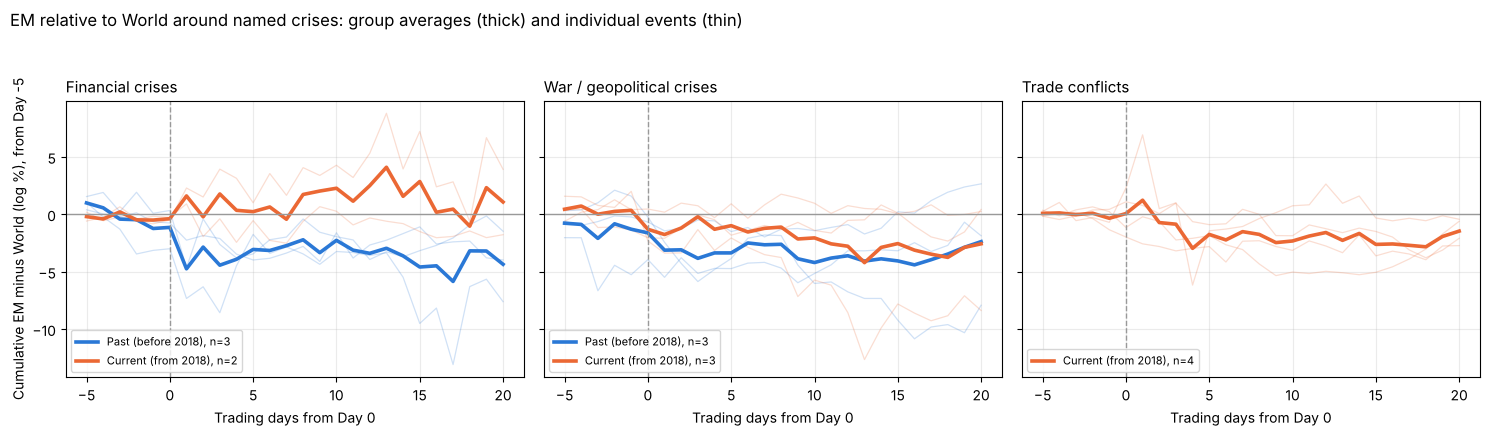

In [11]:
C_PAST, C_CUR = "#2a78d6", "#eb6834"   # same as the team report: past = blue, current = orange
C_TYPE = {"Fin": "#2a78d6", "Geo": "#eb6834", "Trade": "#1baf7a"}
TYPE_TITLE = {"Fin": "Financial crises", "Geo": "War / geopolitical crises", "Trade": "Trade conflicts"}

# Figure 1: average cumulative EM-minus-World path by crisis type, past vs current
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, kind in zip(axes, ["Fin", "Geo", "Trade"]):
    for name in events.index[events["type"] == kind]:          # thin lines = individual events
        ax.plot(paths.index, paths[name], color=C_PAST if events.loc[name, "period"] == "Past" else C_CUR,
                alpha=0.22, lw=0.9)
    for period, colr in [("Past", C_PAST), ("Current", C_CUR)]:  # thick lines = group averages
        key = f"{period} {kind}"
        if key in group_paths:
            n = int((events["group"] == key).sum())
            ax.plot(group_paths.index, group_paths[key], color=colr, lw=2.6,
                    label=f"{period} ({'before' if period == 'Past' else 'from'} 2018), n={n}")
    ax.axhline(0, color="#999999", lw=1)
    ax.axvline(0, color="#999999", lw=1, ls="--")
    ax.set_title(TYPE_TITLE[kind], loc="left", fontsize=11)
    ax.set_xlabel("Trading days from Day 0")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_ylabel(f"Cumulative EM minus World (log %), from Day -{PRE}")
fig.suptitle("EM relative to World around named crises: group averages (thick) and individual events (thin)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIG_DIR / "module_e_fig1_group_paths.png", dpi=160, bbox_inches="tight")
plt.show()

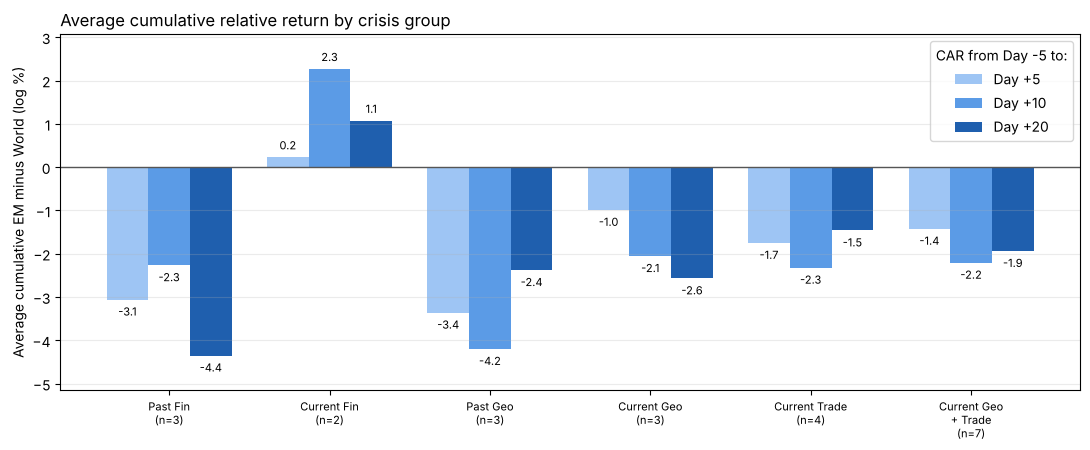

In [12]:
# Figure 2: group-average CAR at Day +5, +10, +20
fig, ax = plt.subplots(figsize=(11, 4.6))
show_h = [5, 10, 20]
width = 0.26
xpos = np.arange(len(GROUP_ORDER))
shades = ["#9ec5f4", "#5b9be6", "#1f5fae"]
for j, h in enumerate(show_h):
    vals = by_group[f"CAR[-{PRE},{h:+d}]"].values
    bars = ax.bar(xpos + (j - 1) * width, vals, width, color=shades[j], label=f"Day {h:+d}")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + (0.12 if v >= 0 else -0.12), f"{v:.1f}",
                ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
ax.axhline(0, color="#555555", lw=1)
ax.margins(y=0.12)                       # room for the value labels
ax.set_xticks(xpos)
ax.set_xticklabels([f"{g.replace(' + ', '\n+ ')}\n(n={int(by_group.loc[g, 'n events'])})" for g in GROUP_ORDER], fontsize=8)
ax.set_ylabel("Average cumulative EM minus World (log %)")
ax.set_title("Average cumulative relative return by crisis group", loc="left", fontsize=12)
ax.grid(axis="y", alpha=0.25)
ax.legend(title=f"CAR from Day -{PRE} to:")
fig.tight_layout()
fig.savefig(FIG_DIR / "module_e_fig2_group_bars.png", dpi=160, bbox_inches="tight")
plt.show()

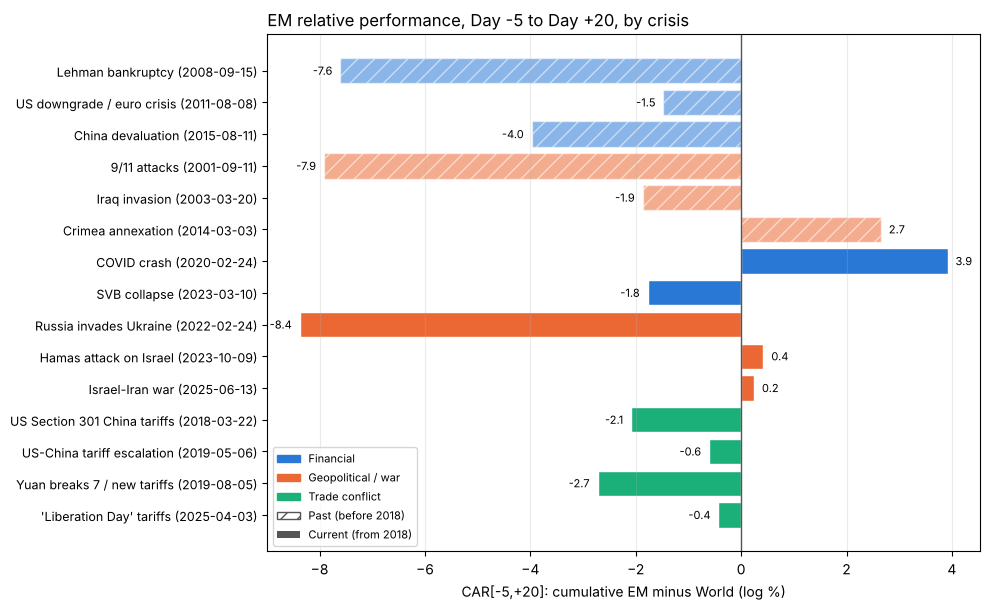

In [13]:
# Figure 3: every crisis, CAR[-5,+20]
order = list(events.index)[::-1]
fig, ax = plt.subplots(figsize=(10, 6.2))
for i, name in enumerate(order):
    past = events.loc[name, "period"] == "Past"
    ax.barh(i, crisis_table.loc[name, FINAL], color=C_TYPE[events.loc[name, "type"]],
            alpha=0.55 if past else 1.0, hatch="//" if past else None, edgecolor="white")
    v = crisis_table.loc[name, FINAL]
    ax.text(v + (0.15 if v >= 0 else -0.15), i, f"{v:.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([f"{n} ({events.loc[n, 'date']:%Y-%m-%d})" for n in order], fontsize=9)
ax.axvline(0, color="#555555", lw=1)
ax.set_xlabel(f"{FINAL}: cumulative EM minus World (log %)")
ax.set_title("EM relative performance, Day -5 to Day +20, by crisis", loc="left", fontsize=12)
ax.legend(handles=[Patch(color=C_TYPE["Fin"], label="Financial"), Patch(color=C_TYPE["Geo"], label="Geopolitical / war"),
                   Patch(color=C_TYPE["Trade"], label="Trade conflict"),
                   Patch(facecolor="white", edgecolor="#555555", hatch="//", label="Past (before 2018)"),
                   Patch(facecolor="#555555", label="Current (from 2018)")], fontsize=8, loc="lower left")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "module_e_fig3_by_crisis.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Reconcile with the team's existing CSV results
The calculation above is written independently (plain pandas on the raw Excel files). Here I compare it with the team's saved tables **without changing either side**. Differences smaller than `1e-8` are floating-point noise.

In [14]:
TOL = 1e-8
checks = []


def compare(label, mine, theirs):
    # Compare numeric tables on their common rows/columns; report anything missing or different.
    idx = theirs.index.intersection(mine.index)
    cols = [c for c in theirs.columns if c in mine.columns]
    d = (mine.loc[idx, cols].astype(float) - theirs.loc[idx, cols].astype(float)).abs()
    max_diff = float(np.nanmax(d.to_numpy())) if d.size else np.nan
    n_missing = (len(theirs.index) - len(idx)) + (len(theirs.columns) - len(cols))
    checks.append({"check": label, "rows": len(idx), "columns": len(cols), "max |diff|": max_diff,
                   "missing rows/cols": n_missing, "consistent": bool(max_diff < TOL and n_missing == 0)})
    return d


def read_team(name, **kw):
    return pd.read_csv(TEAM_TABLES / name, encoding="utf-8-sig", **kw)


# 1) per-event CARs and Day 0 dates (step3_event_study.csv)
t1 = read_team("step3_event_study.csv", index_col=0)
compare("Per-event CARs vs step3_event_study.csv", crisis_table, t1[car_cols])
day0_equal = (t1["day0"].astype(str) == events["day0"].astype(str)).all()
checks.append({"check": "Day 0 dates vs step3_event_study.csv", "rows": len(t1), "columns": 1, "max |diff|": 0.0,
               "missing rows/cols": 0, "consistent": bool(day0_equal)})

# 2) full daily paths (step3_event_paths_daily.csv)
t2 = read_team("step3_event_paths_daily.csv", index_col=0)
t2.index = t2.index.astype(int)
compare("Daily paths, Day -5..+20 x 15 events vs step3_event_paths_daily.csv", paths, t2)

# 3) group means (step3_event_study_by_group.csv)
t3 = read_team("step3_event_study_by_group.csv", index_col=0)
compare("Group means vs step3_event_study_by_group.csv", by_group, t3.drop(columns="n events"))
n_equal = (t3["n events"] == by_group.loc[t3.index, "n events"]).all()
checks.append({"check": "Group sizes vs step3_event_study_by_group.csv", "rows": len(t3), "columns": 1, "max |diff|": 0.0,
               "missing rows/cols": 0, "consistent": bool(n_equal)})

# 4) Q2 write-up tables (q2_table2_*.csv): only the EM-minus-World columns can be checked here
ren = {"CAR[-5,0]": "CAR[-5,+0]", "CAR[-5,+5]": "CAR[-5,+5]", "CAR[-5,+20]": "CAR[-5,+20]"}
t4 = read_team("q2_table2_event_study.csv", index_col=0)[list(ren)].rename(columns=ren)
compare("Per-event CARs vs q2_table2_event_study.csv", crisis_table, t4)

t5 = read_team("q2_table2_event_study_by_group.csv", index_col=0)[list(ren)].rename(columns=ren)
mine_g = by_group[list(ren.values())].copy()
mine_g.loc["Current Geo + Trade"] = tbl.loc[tbl["group"].isin(["Current Geo", "Current Trade"]), list(ren.values())].mean()
compare("Group means vs q2_table2_event_study_by_group.csv (incl. 'Current Geo + Trade')", mine_g, t5)

# 5) Independent identity check straight from index levels:
#    CAR[-5,k] = 100*[ln(EM_k / EM_-6) - ln(World_k / World_-6)]
lv = levels.loc[ret.index.min() - pd.Timedelta(days=10):]          # same inner-joined calendar
ident = {}
for name, row in events.iterrows():
    i0 = lv.index.searchsorted(pd.Timestamp(row["date"]))
    base, end = lv.iloc[i0 - PRE - 1], lv.iloc[i0 + POST]
    ident[name] = 100 * (np.log(end["EM"] / base["EM"]) - np.log(end["WORLD"] / base["WORLD"]))
d = (pd.Series(ident) - crisis_table[FINAL]).abs().max()
checks.append({"check": f"Levels identity check for {FINAL} (raw levels, no returns)", "rows": len(ident), "columns": 1,
               "max |diff|": float(d), "missing rows/cols": 0, "consistent": bool(d < TOL)})

check_df = pd.DataFrame(checks).set_index("check")
check_df["max |diff|"] = check_df["max |diff|"].map(lambda v: f"{v:.2e}")
display(check_df)
print("\nOVERALL:", "ALL CHECKS CONSISTENT" if check_df["consistent"].all() else "DIFFERENCES FOUND - see below")

,rows,columns,max |diff|,missing rows/cols,consistent
check,,,,,
Per-event CARs vs step3_event_study.csv,15,5,4.44e-16,0,True
Day 0 dates vs step3_event_study.csv,15,1,0.00e+00,0,True
"Daily paths, Day -5..+20 x 15 events vs step3_event_paths_daily.csv",26,15,1.78e-15,0,True
Group means vs step3_event_study_by_group.csv,5,5,4.44e-16,0,True
Group sizes vs step3_event_study_by_group.csv,5,1,0.00e+00,0,True
Per-event CARs vs q2_table2_event_study.csv,15,3,4.44e-16,0,True
Group means vs q2_table2_event_study_by_group.csv (incl. 'Current Geo + Trade'),6,3,2.22e-16,0,True
"Levels identity check for CAR[-5,+20] (raw levels, no returns)",15,1,1.49e-13,0,True



OVERALL: ALL CHECKS CONSISTENT


In [15]:
if check_df["consistent"].all():
    print("No differences. The independent recalculation reproduces the team's CSVs to floating-point precision, "
          "so nothing needs to be explained or adjusted.")
else:
    bad = check_df[~check_df["consistent"]]
    print("Items that do not reconcile (nothing has been changed to force a match):")
    display(bad)
    print("Likely causes to check, in this order:\n"
          " 1. Different Day 0 rule (team: first trading day on/after the event date).\n"
          " 2. Different return basis (team: log returns in %, EM and World joined on common dates).\n"
          " 3. Different data vintage (the Excel files or config.py edited after the CSVs were produced).\n"
          " 4. Different window convention (team: cumulative sum starts WITH the Day -5 return).\n"
          " 5. Rounding: results_summary.md and the formatted report show 2 decimals only; use the CSVs.")

No differences. The independent recalculation reproduces the team's CSVs to floating-point precision, so nothing needs to be explained or adjusted.


**Notes on what was and was not checked**
- Everything in the EM − World event study is checked against four team tables (per-event, per-group, daily paths, and the Q2 write-up tables).
- The extra columns in `q2_table2_event_study*.csv` — *currency part*, *local-currency CAR*, *EM ex-IT CAR*, *tech part* — need the local-currency EM series and the EM ex-IT construction (IT weights). They are outside this notebook's scope and were **not** recomputed; they are used below only as a pointer.
- Rounded numbers in `output/results_summary.md` and `report/index.html` are 2-decimal versions of the same CSVs.

## 9. Findings and link to Module D
### 9.1 Numbers used in the summary (computed from the results above)

In [16]:
x = crisis_table[FINAL]
print(f"All events:       mean {FINAL} = {x.mean():+.2f};  {int((x < 0).sum())} of {len(x)} events negative")
for g in GROUP_ORDER:
    r = by_group.loc[g]
    print(f"{g:20s} n={int(r['n events'])}  Day0 {r[f'CAR[-{PRE},+0]']:+.2f}  Day+5 {r[f'CAR[-{PRE},+5]']:+.2f}  "
          f"Day+10 {r[f'CAR[-{PRE},+10]']:+.2f}  Day+20 {r[FINAL]:+.2f}  t(group) {r['t (group)']:+.2f}")
print("\nLike-for-like, current minus past:")
for k, r in like_for_like.iterrows():
    print(f"  {k:36s} {r['current − past']:+.2f}  t {r['t (difference)']:+.2f}")
print("\nWorst: ", x.idxmin(), f"{x.min():+.2f}", "| Best:", x.idxmax(), f"{x.max():+.2f}")
u = country_table.loc["Russia invades Ukraine"]
print(f"Russia invades Ukraine: EM - World {u['EM − World (simple %)']:+.2f} (simple %), of which China {u['China']:+.2f}, "
      f"Taiwan {u['Taiwan']:+.2f}, rest of EM (incl. Russia) {u['rest of EM']:+.2f}")

All events:       mean CAR[-5,+20] = -2.11;  11 of 15 events negative
Past Fin             n=3  Day0 -1.14  Day+5 -3.06  Day+10 -2.27  Day+20 -4.35  t(group) -1.87
Current Fin          n=2  Day0 -0.38  Day+5 +0.23  Day+10 +2.27  Day+20 +1.07  t(group) +0.28
Past Geo             n=3  Day0 -1.62  Day+5 -3.36  Day+10 -4.20  Day+20 -2.38  t(group) -0.82
Current Geo          n=3  Day0 -1.30  Day+5 -0.99  Day+10 -2.05  Day+20 -2.57  t(group) -0.84
Current Trade        n=4  Day0 +0.06  Day+5 -1.75  Day+10 -2.32  Day+20 -1.46  t(group) -0.77
Current Geo + Trade  n=7  Day0 -0.52  Day+5 -1.42  Day+10 -2.21  Day+20 -1.94  t(group) -1.14

Like-for-like, current minus past:
  Financial                            +5.42  t +1.20
  War only                             -0.19  t -0.05
  War + trade (= Geo in equation 2)    +0.44  t +0.13

Worst:  Russia invades Ukraine -8.38 | Best: COVID crash +3.92
Russia invades Ukraine: EM - World -8.00 (simple %), of which China -4.21, Taiwan -1.01, rest of EM (inc

### 9.2 Main findings (event study, EM − World, Day −5 to Day +20)

1. **Most crisis windows are within normal variation.** EM lagged World in 11 of the 15 events, by 2.1 log points on average. But in normal times a 26-day EM − World move has a standard deviation of about 3.9 points, and its 5th–95th percentile range is −6.5 to +6.2. Only three events fall in the bottom 5% of all 26-day windows since 2001: Lehman, 9/11 and Russia–Ukraine. Against pre-event volatility only Russia–Ukraine is significant at 5% (t = −2.0), and point 5 shows that window also holds non-war shocks.
2. **Financial crises: current ones look better, but this rests on two events.** Past financial crises averaged −4.4 at Day +20 and current ones +1.1, a gap of +5.4 points (t ≈ 1.2, not significant). COVID (+3.9) and the SVB collapse (−1.8) point in opposite directions, and COVID's gain comes from China (+5.0 of +2.6 in simple returns), which was already past its first wave in late February 2020.
3. **War and trade crises: no change.** Comparing like with like, as γ4 does in equation (2), past war crises averaged −2.4 and current war + trade crises −1.9, a gap of +0.4 points (t ≈ 0.1). War-only gives −2.6 vs −2.4. This matches γ4 ≈ 0 in the monthly regression.
4. **Pooled "past vs current" overstates the improvement.** All past events average −3.4 and all current events −1.3, but the gap comes from financial crises only: for wars there is none, and trade conflicts have no past counterpart.
5. **The worst current event is not only about the war.** The country breakdown splits Russia–Ukraine's −8.0 (simple %) into China −4.2, Taiwan −1.0 and the rest of EM −3.3. The rest includes Russia's removal from MSCI EM (9 March 2022: EM − World −3.4 that day). China's part comes mostly from its sell-off on 11–15 March 2022 (−3.7%, −8.0%, −6.3% in three days), driven by China-specific news (a COVID lockdown in Shenzhen, US warnings on delisting Chinese ADRs) as well as fears of sanctions over China's ties to Russia.
6. **China drives EM's losses in the US–China trade conflicts.** China is the largest negative contributor in all four trade events (−1.5, −2.2, −0.7 and −1.5 points). In May 2019 and April 2025 India (+0.8, +1.2) offset much of it, which is why those two windows end close to zero.

### 9.3 How this complements the Module D crisis regression
Module D (equation 2, `step3_crisis_regressions.csv`) regresses the **monthly** EM − World return on crisis flags (Fin, Geo, and their interactions with a "Current" dummy), with a structural-break dummy (Post). The event study looks at the **same question at a different frequency and scope**. Because Geo in equation (2) includes trade-policy spikes, γ4 is compared with the **war + trade** event contrast.

In [17]:
reg = read_team("step3_crisis_regressions.csv", index_col=0)
rows = ["g1 Fin", "g2 Geo", "g3 Fin x Current", "g4 Geo x Current", "theta Post",
        "g1+g3 (current Fin)", "g2+g4 (current Geo)"]
out = {}
for col in ["EM - World, no X", "EM - World, with X"]:
    out[(col, "coef")] = [reg.loc[r, col] for r in rows]
    out[(col, "t-stat")] = [reg.loc[f"t: {r}", col] for r in rows]
module_d = pd.DataFrame(out, index=rows)
print("Module D, equation (2), dependent variable = monthly EM - World (log %); Newey-West t-stats; N =",
      int(reg.loc["N", "EM - World, no X"]))
display(module_d.round(2))

# Same 'current minus past' contrast, from the event study (mean CAR at +20), like for like
contrast = like_for_like[[f"past mean {FINAL}", f"current mean {FINAL}", "current − past", "t (difference)"]].copy()
contrast.columns = ["Event study: Past mean", "Event study: Current mean", "Event study: Current - Past", "Event study: t"]
contrast["Module D interaction (no X)"] = [reg.loc["g3 Fin x Current", "EM - World, no X"], np.nan,
                                           reg.loc["g4 Geo x Current", "EM - World, no X"]]
contrast["Module D t-stat"] = [reg.loc["t: g3 Fin x Current", "EM - World, no X"], np.nan,
                               reg.loc["t: g4 Geo x Current", "EM - World, no X"]]
print(f"Past-vs-current contrast: event study ({FINAL}, log points over 26 days) vs Module D (per month, log points).")
print("Module D has no war-only term: Geo covers war and trade together.")
display(contrast.round(2))

Module D, equation (2), dependent variable = monthly EM - World (log %); Newey-West t-stats; N = 309


EM - World, no X        EM - World, with X       
                                coef t-stat               coef t-stat
g1 Fin                          0.00   0.00               0.05   0.12
g2 Geo                          0.07   0.07              -0.07  -0.06
g3 Fin x Current               -0.03  -0.04               0.03   0.05
g4 Geo x Current                0.19   0.16               0.40   0.31
theta Post                     -1.51  -3.12              -1.32  -2.88
g1+g3 (current Fin)            -0.03  -0.04               0.09   0.14
g2+g4 (current Geo)             0.26   0.45               0.33   0.62

Past-vs-current contrast: event study (CAR[-5,+20], log points over 26 days) vs Module D (per month, log points).
Module D has no war-only term: Geo covers war and trade together.


,Event study: Past mean,Event study: Current mean,Event study: Current - Past,Event study: t,Module D interaction (no X),Module D t-stat
Financial,-4.35,1.07,5.42,1.20,-0.03,-0.04
War only,-2.38,-2.57,-0.19,-0.05,NaN,NaN
War + trade (= Geo in equation 2),-2.38,-1.94,0.44,0.13,0.19,0.16


**What the two modules say together**

- **Module D answers "on average, are crisis months different?"** None of the four crisis coefficients (γ1–γ4) is statistically significant, and the current-period totals are also insignificant. The only strong effect is the structural-break term (θ Post, about −1.3 to −1.5 per month), which says EM relative returns fell after the break regardless of crises.
- **Module E answers "what happens in the weeks around specific, named shocks?"** Measured like for like, war and trade crises show no change between past and current (+0.4 points, t ≈ 0.1), the same message as γ4. Financial crises look better today (+5.4 points), but with two current events and t ≈ 1.2 this is suggestive only, and γ3 in the monthly regression is about zero.
- **Why they can differ for financial crises.** The `Fin` flag in Module D is switched on for long recovery periods (134 of 309 months), so it blends acute shocks with calmer months; the event study isolates 26-day windows around the sharpest dates.
- **How to use them.** Module D is the formal test. Module E shows the timing, the size and the heterogeneity behind it. The country breakdown shows that some windows are driven by unrelated country shocks (China in March 2022), which is a reason not to read single events as the effect of the crisis.
- **Pointer to a further decomposition.** The team's `q2_table2_event_study.csv` splits each event into a currency part and a local-currency part; it shows that dollar moves matter for how EM looks against World in a crisis, consistent with the strong ΔDXY coefficient in Module D's "with X" columns.

### 9.4 Limitations
- Small groups (2–7 events), equal weights. Group t-statistics treat events as independent and use pre-event volatility, which is lower than crisis volatility, so they overstate significance.
- The window includes Day −5 to Day −1, so any pre-event drift is part of every `CAR[-5,k]`.
- Other news inside a window is not removed (e.g. China's March 2022 sell-off, Russia's index deletion); the country breakdown shows where this matters.
- The country breakdown is only partial for past crises (Taiwan, Korea, China and India before 2010).
- MSCI World contains no EM stocks but includes the US, so EM − World is relative to developed markets, not to the US alone.
- Event dates and the Past/Current and Fin/Geo/Trade labels are the team's definitions and were not changed.